# 02 - Cleaning & validation

Runs the reusable pipeline in `src/cleaning.py` and documents the evidence behind each cleaning decision (see `docs/decisions_log.md`).

**Principle:** flag, don't delete. Only true duplicates (reviews, geolocation) are collapsed.

In [1]:
import sys, json
sys.path.insert(0, '..')
import pandas as pd
import matplotlib.pyplot as plt
from src import cleaning

clean, log, results = cleaning.run('../data/raw', '../data/clean')

table                       rows  cols
orders                    99,441  18
order_items              112,650  8
order_payments           103,886  6
order_reviews             98,673  8
customers                 99,441  5
sellers                    3,095  4
products                  32,951  11
category_translation          74  2
geolocation               19,010  6

Validation
  [PASS] PK orders.order_id unique  
  [PASS] PK customers.customer_id unique  
  [PASS] PK products.product_id unique  
  [PASS] PK sellers.seller_id unique  
  [PASS] PK order_reviews.order_id unique  
  [PASS] PK order_items (order_id, order_item_id) unique  
  [PASS] PK order_payments (order_id, payment_sequential) unique  
  [PASS] PK geolocation.zip_prefix unique  
  [PASS] FK orders.customer_id -> customers.customer_id  0 orphan rows
  [PASS] FK order_items.order_id -> orders.order_id  0 orphan rows
  [PASS] FK order_items.product_id -> products.product_id  0 orphan rows
  [PASS] FK order_items.seller_id -> s

## 1. Validation summary

In [2]:
v = pd.DataFrame(results)
v['status'] = v.apply(lambda r: 'PASS' if r.passed else ('FAIL' if r.hard else 'WARN'), axis=1)
v[['status','check','detail']]

,status,check,detail
0,PASS,PK orders.order_id unique,
1,PASS,PK customers.customer_id unique,
2,PASS,PK products.product_id unique,
3,PASS,PK sellers.seller_id unique,
4,PASS,PK order_reviews.order_id unique,
5,PASS,"PK order_items (order_id, order_item_id) unique",
6,PASS,"PK order_payments (order_id, payment_sequentia...",
7,PASS,PK geolocation.zip_prefix unique,
8,PASS,FK orders.customer_id -> customers.customer_id,0 orphan rows
9,PASS,FK order_items.order_id -> orders.order_id,0 orphan rows


## 2. The fan-out trap, quantified
Joining items to payments at row level duplicates `price` for every extra payment row.

In [3]:
pd.Series(log['fanout_demo'])

item_price_sum                      13591643.70
naive_items_x_payments_price_sum    14209115.34
inflation_pct                              4.54
dtype: float64

## 3. `customer_id` vs `customer_unique_id`
Olist issues a new `customer_id` per order; the real person is `customer_unique_id`.

In [4]:
o, c = clean['orders'], clean['customers']
m = o.merge(c[['customer_id','customer_unique_id']], on='customer_id')
per_person = m.groupby('customer_unique_id').size()
print('orders:', len(o), '| customer_ids:', c.customer_id.nunique(), '| real customers:', c.customer_unique_id.nunique())
print('customers with 2+ orders:', (per_person > 1).sum(), f'({(per_person > 1).mean():.1%})')
per_person.value_counts().sort_index().head(8)

orders: 99441 | customer_ids: 99441 | real customers: 96096
customers with 2+ orders: 2997 (3.1%)


1    93099
2     2745
3      203
4       30
5        8
6        6
7        3
9        1
Name: count, dtype: int64

## 4. Order status and the sale flag

In [5]:
pd.DataFrame({'orders': o.order_status.value_counts(), 'share_%': (o.order_status.value_counts(normalize=True)*100).round(2)})

,orders,share_%
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


Orders with no items are almost entirely `unavailable`/`canceled`, which supports excluding them from revenue via `is_valid_sale`.

In [6]:
o[~o.has_items].order_status.value_counts()

order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

## 5. Monthly order volume: where is the data trustworthy?
Shaded months fall outside the analysis window (`in_analysis_window = False`).

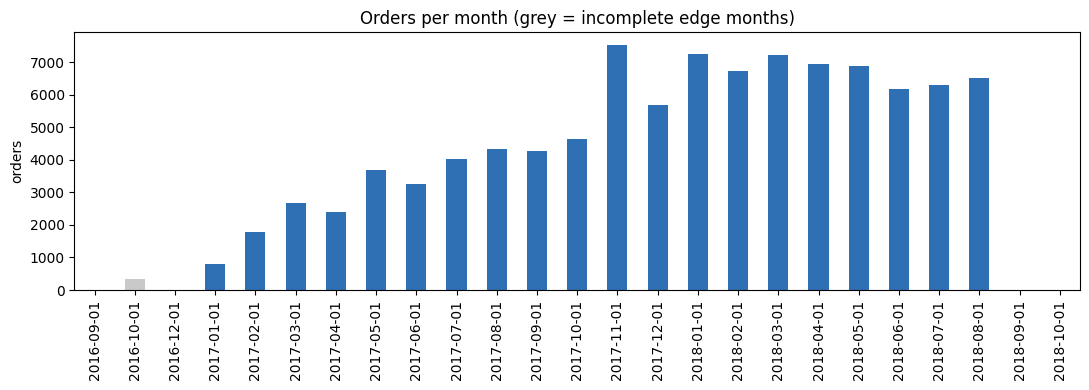

In [7]:
monthly = o.groupby('purchase_month').size()
fig, ax = plt.subplots(figsize=(11,4))
monthly.plot(kind='bar', ax=ax, color=['#c9c9c9' if (m < '2017-01-01' or m >= '2018-09-01') else '#2f6fb3' for m in monthly.index])
ax.set_title('Orders per month (grey = incomplete edge months)'); ax.set_xlabel(''); ax.set_ylabel('orders')
plt.tight_layout(); plt.show()

## 6. Delivery metrics sanity check

       delivery_days  estimated_days  delay_days
count        96470.0         96470.0     96470.0
mean            12.6            23.7       -11.2
std              9.5             8.8        10.2
min              0.5             2.0      -146.0
25%              6.8            18.3       -16.2
50%             10.2            23.2       -11.9
75%             15.7            28.4        -6.4
max            209.6           155.1       189.0

Late deliveries: 7,826 of 96,470 (8.1%)
Orders with timestamp-sequence anomalies (kept, flagged): 189


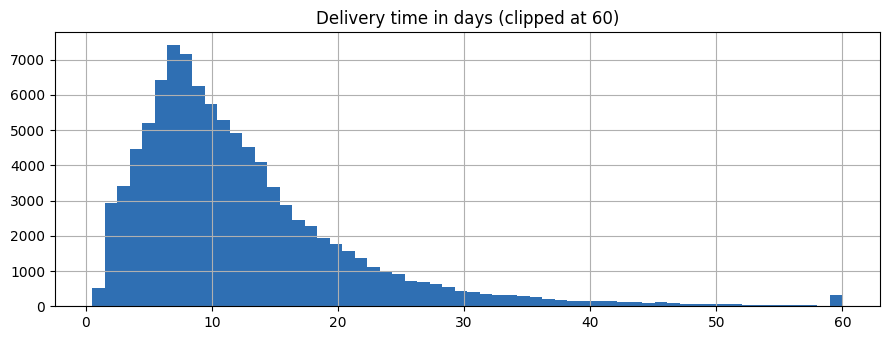

In [8]:
d = o[o.is_delivered]
print(d[['delivery_days','estimated_days','delay_days']].describe().round(1))
print(f"\nLate deliveries: {d.is_late.sum():,} of {len(d):,} ({d.is_late.mean():.1%})")
print('Orders with timestamp-sequence anomalies (kept, flagged):', o.ts_anomaly.sum())
fig, ax = plt.subplots(figsize=(9,3.5))
d.delivery_days.clip(upper=60).hist(bins=60, ax=ax, color='#2f6fb3')
ax.set_title('Delivery time in days (clipped at 60)'); plt.tight_layout(); plt.show()

## 7. Reviews: one per order

In [9]:
pd.Series(log['order_reviews'])

rows_before                                                            99224
rows_after                                                             98673
rows_dropped                                                             551
orders_with_multiple_reviews                                             547
duplicate_review_ids_in_raw                                              814
review_id_unique_after                                                 False
note                            grain is one review per order; PK = order_id
dtype: object

## 8. Products, categories and geolocation

In [10]:
print(json.dumps(log['products'], indent=1))
print(json.dumps(log['geolocation'], indent=1))

{
 "rows": 32951,
 "missing_category_filled_unknown": 610,
 "untranslated_categories_mapped_manually": [
  "pc_gamer",
  "portateis_cozinha_e_preparadores_de_alimentos"
 ],
 "still_untranslated_rows": 0,
 "missing_dimensions": 2
}
{
 "rows_raw": 1000163,
 "exact_duplicate_rows": 279669,
 "points_outside_brazil_dropped": 42,
 "rows_clean": 19010,
 "note": "collapsed to one row per zip prefix (median lat/lng, modal city/state)"
}


## Next
Phase 2: design the PostgreSQL schema and load these clean CSVs (`sql/01_schema.sql`, `sql/02_load.sql`).